<a href="https://colab.research.google.com/github/venkataratnamb20/quicksilicon/blob/notebooks/adc_dashboard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ADC: Dashboard


## Setup


In [1]:
def environment():
    try:
        get_ipython()
        print('notebook')
        return str(get_ipython())
    except:
        print('server')
        return 'server'
env = environment()

if env=="server":
   theme="fast"
else:
   theme="simple"

if 'google.colab' in env:
    print('Running on CoLab')
    !pip install panel hvplot
    !pip install bokeh_sampledata


notebook
Running on CoLab
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.5/175.5 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.7/17.7 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.3/242.3 kB 7.7 MB/s eta 0:00:00


In [2]:
import hvplot.pandas
import holoviews as hv

hv.extension('bokeh')

In [3]:
import os
import sys
# sys.path.insert(0, os.path.abspath('../..'))
import yaml

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')


import panel as pn
import hvplot.pandas
import holoviews as hv
from holoviews import opts
import param


# global_css_files = [
#     # "https://cdn.jsdelivr.net/npm/bootstrap@5.3.3/dist/css/bootstrap.css",
#     "https://cdn.jsdelivr.net/npm/bootstrap@5.3.3/dist/css/bootstrap.min.css",
#     # "https://cdn.jsdelivr.net/npm/bootstrap-icons@1.10.5/font/bootstrap-icons.css",
#     # pn.template.FastListTemplate.default_css
# ]
# # title_styles = {"border": "1px solid black"}
# title_styles = dict(border = "1px solid black",
#                     padding = "10px"
#                     )

# pn.config.raw_css = global_css_files
# pn.config.raw_js = [
#     "https://cdn.jsdelivr.net/npm/bootstrap@5.3.3/dist/js/bootstrap.bundle.min.js",
# ]

pn.extension('plotly',
             sizing_mode="stretch_width",
             template="fast",
             design="material",
             loading_indicator=True,
            #  global_css = global_css_files
             )

class AdcDashboard:
    def __init__(self, title: str = 'Dashboard'):
        self.title = title
        self.header_styles = {"border" : "1px solid black",
                                  "padding" : "2px",
                                  "background" : "lightgray",
                                  "color" : "##444",
                                  "margin" : "10px 0",
                                  "width" : "200px"
                                   }

    def create_header(self, title):
        return pn.panel(title, styles = self.header_styles)

    def dashboard(self):
        _dashboard = pn.Column(self.create_header("ADC Dashboard")),
        return _dashboard

    def view(self):
        return self.create_header(self.title)

adc_dash = AdcDashboard()
adc_dash.view().servable()

Markdown(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width', styles={'border': '1px solid blac...})

ERROR:tornado.application:Exception in callback functools.partial(<bound method IOLoop._discard_future_result of <tornado.platform.asyncio.AsyncIOMainLoop object at 0x7c124b3a45f0>>, <Task finished name='Task-5' coro=<ParamRef._eval_async() done, defined at /usr/local/lib/python3.12/dist-packages/panel/param.py:879> exception=NameError("name 'asyncio' is not defined")>)
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/tornado/ioloop.py", line 750, in _run_callback
    ret = callback()
          ^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/tornado/ioloop.py", line 774, in _discard_future_result
    future.result()
  File "/usr/local/lib/python3.12/dist-packages/panel/param.py", line 913, in _eval_async
    raise e
  File "/usr/local/lib/python3.12/dist-packages/panel/param.py", line 892, in _eval_async
    async for new_obj in awaitable:
  File "/tmp/ipython-input-2202478057.py", line 16, in slideshow
    img, _ = await asyncio.gather(resp

### Styles

```
<link href="https://cdn.jsdelivr.net/npm/bootstrap@5.3.3/dist/css/bootstrap.min.css" rel="stylesheet" integrity="sha384-QWTKZyjpPEjISv5WaRU9OFeRpok6YctnYmDr5pNlyT2bRjXh0JMhjY6hW+ALEwIH" crossorigin="anonymous">

<script src="https://cdn.jsdelivr.net/npm/bootstrap@5.3.3/dist/js/bootstrap.bundle.min.js" integrity="sha384-YvpcrYf0tY3lHB60NNkmXc5s9fDVZLESaAA55NDzOxhy9GkcIdslK1eN7N6jIeHz" crossorigin="anonymous"></script>
```

In [4]:

# class="p-5 text-primary bg-primary-subtle border border-primary-subtle rounded-3"

# title_wid = pn.pane.HTML("""
# <div class="p-1 color-primary bg-primary-subtle text-center">
#   <h1>Dashboard</h1>
# </div>""", align='center',
#                          styles=title_styles,
#                         #  css_classes=['btn', 'btn-primary']
#                          )

title_wid = """
<div class="p-1 text-primary bg-primary-subtle text-center">
  <h1 class="bg-primary">Dashboard</h1>
</div>
"""
card_wid = """

<div class="card text-center mb-3" style="width: 28rem;">
  <div class="card-body">
    <h5 class="card-title">Special title treatment</h5>
    <p class="card-text">With supporting text below as a natural lead-in to additional content.</p>
    <a href="#" class="btn btn-primary">Go somewhere</a>
  </div>
</div>

"""
get_primary_btn = lambda name: pn.widgets.Button(name=str(name),
                                                #  css_classes=['btn', 'btn-primary'],
                                                 button_type='primary',
                                                 width=50,
                                                 )
nbit_btns = [get_primary_btn(i) for i in range(8, 19)]
dashboard = pn.Column(title_wid,
                      pn.Row(*nbit_btns, align='center'),
                      card_wid, align="center"
                    )
dashboard.servable()

Column(align='center', design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] Markdown(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [1] Row(align='center', design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
        [0] Button(button_type='primary', design=<class 'panel.theme.materi..., name='8', width=50)
        [1] Button(button_type='primary', design=<class 'panel.theme.materi..., name='9', width=50)
        [2] Button(button_type='primary', design=<class 'panel.theme.materi..., name='10', width=50)
        [3] Button(button_type='primary', design=<class 'panel.theme.materi..., name='11', width=50)
        [4] Button(button_type='primary', design=<class 'panel.theme.materi..., name='12', width=50)
        [5] Button(button_type='primary', design=<class 'panel.theme.materi..., name='13', width=50)
        [6] Button(button_type='primary', design=<class 'panel.theme.materi..., name='14', width=50)
        [7] Button(button_type='primary', design=<class 'panel.theme.materi..., name='15', width=50)
        [8] Button(button_type='primary', design=<class 'panel.theme.materi..., name='16', width=50)
        [9] Button(button_type='primary', design=<class 'panel.theme.materi..., name='17', width=50)
        [10] Button(button_type='primary', design=<class 'panel.theme.materi..., name='18', width=50)
    [2] Markdown(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

## Dashboard1:

In [5]:
pn.extension(
    design="material",
    sizing_mode="stretch_width"
    )


main_outer_style = {
    'background': '#f9f9f9',
    'border-radius': '5px',
    'border': '2px solid black',
    'padding': '4px',
    'box-shadow': '5px 5px 5px #bcbcbc',
    'margin': "1px",
}

header = pn.panel("ADC", align='center',
                  styles={'font-size': '2em',
                          'background-color': '#333',
                          'color': '#ddd',
                          'padding': '0.4em 2em'})
# btn_wid_col = pn.Column(*[pn.widgets.Button(name=str(i), width
#  = 100, button_type='primary') \
#                       for i in range(8, 15)])

btn_wid_col = pn.Column(
    pn.widgets.FloatInput(name='VREFP', value = 1.5, start = 1.0, end = 10, step = 0.5),
    pn.widgets.FloatInput(name='VREFM', value = 0, start = -10.0, end = 10, step = 0.5)
    )
#

btn_wid_row = pn.Row(*[pn.widgets.Button(name=str(i/2), width
 = 100, button_type='primary') \
                      for i in range(2, 10)])

result_wid = pn.Column(
    pn.Card('plot'),
    pn.Card('data'),
    styles = main_outer_style,
    align = 'center'
)
main_widget = pn.Column(btn_wid_row,
                        pn.Row(
                            btn_wid_col,
                            result_wid
                            ))
pn.Column(
    header,
    main_widget
)

Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] Markdown(str, align='center', design=<class 'panel.theme.materi..., sizing_mode='stretch_width', styles={'font-size': '2em', ...})
    [1] Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
        [0] Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
            [0] Button(button_type='primary', design=<class 'panel.theme.materi..., name='1.0', width=100)
            [1] Button(button_type='primary', design=<class 'panel.theme.materi..., name='1.5', width=100)
            [2] Button(button_type='primary', design=<class 'panel.theme.materi..., name='2.0', width=100)
            [3] Button(button_type='primary', design=<class 'panel.theme.materi..., name='2.5', width=100)
            [4] Button(button_type='primary', design=<class 'panel.theme.materi..., name='3.0', width=100)
            [5] Button(button_type='primary', design=<class 'panel.theme.materi..., name='3.5', width=100)
            [6] Button(button_type='primary', design=<class 'panel.theme.materi..., name='4.0', width=100)
            [7] Button(button_type='primary', design=<class 'panel.theme.materi..., name='4.5', width=100)
        [1] Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
            [0] Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
                [0] FloatInput(design=<class 'panel.theme.materi..., end=10, name='VREFP', sizing_mode='stretch_width', start=1.0, step=0.5, value=1.5)
                [1] FloatInput(design=<class 'panel.theme.materi..., end=10, name='VREFM', sizing_mode='stretch_width', start=-10.0, step=0.5)
            [1] Column(align='center', design=<class 'panel.theme.materi..., sizing_mode='stretch_width', styles={'background': '#f9f9f9', ...})
                [0] Card(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
                    [0] Markdown(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
                [1] Card(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
                    [0] Markdown(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# lsb
nbit = 12
vref = 1.5
lsb = vref / (2**nbit - 1)
# filename = '/content/saradc250924_nose_dc_vout_dec.csv'
filename = '/content/saradc250924_nose_dc_vout_dec2_conservative_nfmin1.csv'
df = pd.read_csv(filename, dtype='str')
df.rename(columns=dict(zip(df.columns, ('xtime', 'code'))), inplace=True)
df.xtime = df.xtime.astype(float)
df.set_index('xtime', inplace=True)
df['vout'] = df.code.apply(lambda x: int(x, 2)*lsb)
df.head()

,code,vout
xtime,,
9.425688e-07,101111111111,1.124908
1.942569e-06,101111111111,1.124908
2.942569e-06,101111111111,1.124908
3.942569e-06,101111111111,1.124908
4.942569e-06,101111111111,1.124908


In [88]:
df.dtypes


,0
code,object
vout,float64


In [89]:
df.size

240

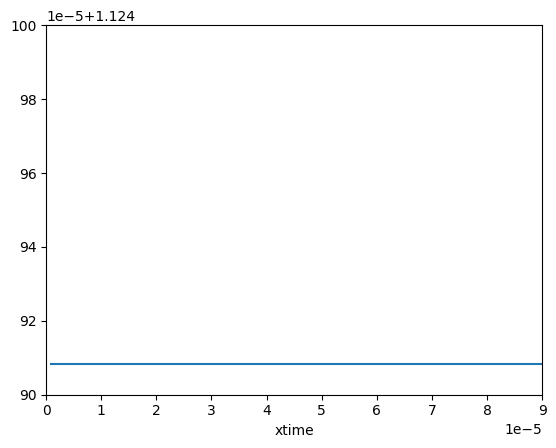

In [90]:
# df.vout.plot(xlim=(0, 95), ylim=(1.1249, 1.125))
df.vout.plot(xlim=(0, 90e-6), ylim=(1.1249, 1.125))
# df.vout.plot(ylim=(1.1249, 1.125))
plt.show()

In [91]:
# df.vout[df.index < 90e-6] == 1.12490842
df.vout[df.index < 100e-6].unique()


array([1.12490842])

# Appendix


## Panel


In [6]:

# With Spacer
import panel as pn

pn.extension()
pn.config.throttled = True

In [7]:


image = pn.pane.PNG("https://assets.holoviz.org/panel/tutorials/wind_turbine.png", sizing_mode="scale_both")

card1 = pn.Card(image, title='Turbine 1', height=150, width=200, align="center")
card2 = pn.Card(image, title='Turbine 2', height=150, width=200, align="center")
spacer1 = pn.Spacer(height=33)
spacer2 = pn.Spacer(height=33)
spacer3 = pn.Spacer(height=33)

pn.Column(
    spacer1, card1, spacer2, card2, spacer3,
    sizing_mode="fixed", width=400, height=400, styles={"border": "1px solid black"}
).servable()

Column(design=<class 'panel.theme.materi..., height=400, sizing_mode='fixed', styles={'border': '1px s...}, width=400)
    [0] Spacer(design=<class 'panel.theme.materi..., height=33, sizing_mode='stretch_width')
    [1] Card(align='center', design=<class 'panel.theme.materi..., height=150, sizing_mode='fixed', title='Turbine 1', width=200)
        [0] PNG(str, design=<class 'panel.theme.materi..., sizing_mode='scale_both')
    [2] Spacer(design=<class 'panel.theme.materi..., height=33, sizing_mode='stretch_width')
    [3] Card(align='center', design=<class 'panel.theme.materi..., height=150, sizing_mode='fixed', title='Turbine 2', width=200)
        [0] PNG(str, design=<class 'panel.theme.materi..., sizing_mode='scale_both')
    [4] Spacer(design=<class 'panel.theme.materi..., height=33, sizing_mode='stretch_width')

In [8]:
# Custom Component with PyComponent

from panel.custom import PyComponent
from panel.widgets import WidgetBase

class CounterButton(PyComponent, WidgetBase):

    value = param.Integer(default=0)

    def __panel__(self):
        return pn.widgets.Button(
            name=self._button_name, on_click=self._on_click
        )

    def _on_click(self, event):
        self.value += 1

    @param.depends("value")
    def _button_name(self):
        return f"count is {self.value}"

CounterButton()

CounterButton(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

### templates


In [9]:
widget = pn.widgets.TextInput(value='world')

def hello_world(text):
    return f'Hello {text}!'

pn.Row(widget, pn.bind(hello_world, widget)).servable()

Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] TextInput(design=<class 'panel.theme.materi..., sizing_mode='stretch_width', value='world')
    [1] ParamFunction(function, _pane=Markdown, defer_load=False, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [10]:
# with align and margin
import panel as pn

pn.extension()

image = pn.pane.PNG("https://assets.holoviz.org/panel/tutorials/wind_turbine.png", sizing_mode="scale_both")

card1 = pn.Card(image, title='Turbine 1', height=150, width=200, align="center", margin=(33,0,17,0))
card2 = pn.Card(image, title='Turbine 2', height=150, width=200, align="center", margin=(16,0,33,0))

pn.Column(
    card1, card2,
    sizing_mode="fixed", width=400, height=400, styles={"border": "1px solid black"}
).servable()

Column(design=<class 'panel.theme.materi..., height=400, sizing_mode='fixed', styles={'border': '1px s...}, width=400)
    [0] Card(align='center', design=<class 'panel.theme.materi..., height=150, margin=(33, 0, 17, 0), sizing_mode='fixed', title='Turbine 1', width=200)
        [0] PNG(str, design=<class 'panel.theme.materi..., sizing_mode='scale_both')
    [1] Card(align='center', design=<class 'panel.theme.materi..., height=150, margin=(16, 0, 33, 0), sizing_mode='fixed', title='Turbine 2', width=200)
        [0] PNG(str, design=<class 'panel.theme.materi..., sizing_mode='scale_both')

### Styles

In [11]:
import panel as pn

pn.extension()

outer_style = {
    'background': '#f9f9f9',
    'border-radius': '5px',
    'border': '2px solid black',
    'padding': '20px',
    'box-shadow': '5px 5px 5px #bcbcbc',
    'margin': "10px",
}

pn.indicators.Number(
    name="Wind Speed",
    value=8.6,
    format="{value} m/s",
    colors=[(10, "green"), (100, "red")],
    styles=outer_style,
).servable()

Number(colors=[(10, 'green'), ...], design=<class 'panel.theme.materi..., format='{value} m/s', name='Wind Speed', styles={'background': '#f9f9f9', ...}, value=8.6)

In [12]:
import panel as pn

pn.extension()

outer_style = {
    'background': '#f9f9f9',
    'border-radius': '5px',
    'border': '2px solid black',
    'padding': '20px',
    'box-shadow': '5px 5px 5px #bcbcbc',
    'margin': "10px",
}

inner_stylesheet = """
div:nth-child(2) {
  background-color: pink;
  border-radius: 5px;
  padding: 10px;
  margin: 10px;
}
"""

pn.indicators.Number(
    name="Wind Speed",
    value=8.6,
    format="{value} m/s",
    colors=[(10, "green"), (100, "red")],
    styles=outer_style,
    stylesheets=[inner_stylesheet]
).servable()


Number(colors=[(10, 'green'), ...], design=<class 'panel.theme.materi..., format='{value} m/s', name='Wind Speed', styles={'background': '#f9f9f9', ...}, stylesheets=['\ndiv:nth-child(2) {...], value=8.6)

In [13]:
custom_style = {
    'background': '#f9f9f9',
    'border': '1px solid black',
    'padding': '10px',
    'box-shadow': '5px 5px 5px #bcbcbc'
}

pn.widgets.FloatSlider(name='Number', styles=custom_style)

FloatSlider(design=<class 'panel.theme.materi..., name='Number', sizing_mode='stretch_width', styles={'background': '#f9f9f9', ...})

In [14]:
# css variables
stylesheet = """
:host {
  --handle-width: 15px;
  --handle-height: 25px;
  --slider-size: 25px;
}
"""

pn.widgets.FloatSlider(
    name='Number', styles=custom_style, stylesheets=[stylesheet]
)

FloatSlider(design=<class 'panel.theme.materi..., name='Number', sizing_mode='stretch_width', styles={'background': '#f9f9f9', ...}, stylesheets=['\n:host {\n  ...])

In [15]:
stylesheet = """
:host {
  --slider-size: 5px;
  --handle-width: 16px;
  --handle-height: 16px;
}

.noUi-handle {
  border-radius: 100%;
  box-shadow: unset;
  background-color: #0081f3;
}
"""

pn.widgets.FloatSlider(
    name='Number', styles=custom_style, stylesheets=[stylesheet]
)

FloatSlider(design=<class 'panel.theme.materi..., name='Number', sizing_mode='stretch_width', styles={'background': '#f9f9f9', ...}, stylesheets=['\n:host {\n  ...])

In [16]:
# External Stylesheets
pn.widgets.FloatSlider(
    name='Number', stylesheets=['https://assets.holoviz.org/panel/how_to/styling/noUi.css']
)

FloatSlider(design=<class 'panel.theme.materi..., name='Number', sizing_mode='stretch_width', stylesheets=['https://assets.holoviz.o...])

In [17]:
# css classes

color_stylesheet = """
:host(.red) .noUi-handle {
  background-color: red
}

:host(.green) .noUi-handle {
  background-color: green
}

:host(.blue) .noUi-handle {
  background-color: blue
}
"""

pn.Column(
    *(pn.widgets.FloatSlider(name='Number', stylesheets=[stylesheet, color_stylesheet], css_classes=[cls])
      for cls in ('red', 'green', 'blue'))
)

Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] FloatSlider(css_classes=['red'], design=<class 'panel.theme.materi..., name='Number', sizing_mode='stretch_width', stylesheets=['\n:host {\n  --slider-si...])
    [1] FloatSlider(css_classes=['green'], design=<class 'panel.theme.materi..., name='Number', sizing_mode='stretch_width', stylesheets=['\n:host {\n  --slider-si...])
    [2] FloatSlider(css_classes=['blue'], design=<class 'panel.theme.materi..., name='Number', sizing_mode='stretch_width', stylesheets=['\n:host {\n  --slider-si...])

In [18]:
run = pn.widgets.Button(name="Press to run calculation", align='center')

def runner(run):
    if not run:
        yield "Calculation did not run yet"
        return
    for i in range(101):
        time.sleep(0.05) # Some calculation
        yield pn.Column(
            f'Running ({i}/100%)', pn.indicators.Progress(value=i)
        )
    yield "Success ✅︎"
pn.Row(run, pn.bind(runner, run))

Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] Button(align='center', design=<class 'panel.theme.materi..., name='Press to run c..., sizing_mode='stretch_width')
    [1] ParamFunction(function, _pane=Str, defer_load=False, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [19]:
import random

async def slideshow():
    index = 0
    while True:
        url = f"https://picsum.photos/800/300?image={index}"

        if pn.state._is_pyodide:
            from pyodide.http import pyfetch
            img, _ = await asyncio.gather(pyfetch(url), asyncio.sleep(1))
            yield pn.pane.JPG(await img.bytes())

        import aiohttp
        async with aiohttp.ClientSession() as session:
            async with session.get(url) as resp:
                img, _ = await asyncio.gather(resp.read(), asyncio.sleep(1))
                yield pn.pane.JPG(img)
        index = (index + 1) % 10

pn.Row(slideshow)

Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] ParamFunction(function, _pane=Str, defer_load=False, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

### param

In [20]:
import panel as pn

pn.extension(design="material")

component = pn.panel("Hello World")

pn.Row(
    component.param, pn.pane.HTML(component.param._repr_html_())
).servable()

Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] Column(design=<class 'panel.theme.materi..., margin=(5, 10), name='Markdown', sizing_mode='stretch_width')
        [0] StaticText(design=<class 'panel.theme.materi..., sizing_mode='stretch_width', value='<b>Markdown</b>')
        [1] LiteralInput(description='Whether the object should..., design=<class 'panel.theme.materi..., name='Align', sizing_mode='stretch_width', value='start')
        [2] LiteralInput(description='Describes the proportiona..., design=<class 'panel.theme.materi..., name='Aspect ratio', sizing_mode='stretch_width')
        [3] ListInput(description='CSS classes t..., design=<class 'panel.theme.materi..., name='Css classes', sizing_mode='stretch_width', type=<class 'list'>)
        [4] Row(design=<class 'panel.theme.materi..., width=300)
            [0] Select(description='The design system t..., design=<class 'panel.theme.materi..., margin=(5, 0, 5, 10), name='Design', options=OrderedDict({'None': None,...]), sizing_mode='stretch_width', value=<class 'panel.theme.materi...)
            [1] Toggle(align='end', button_type='primary', design=<class 'panel.theme.materi..., height_policy='fit', margin=(0, 0, 5, 10), max_height=30, max_width=20, name='⋮', sizing_mode='stretch_width')
        [5] IntInput(description='The height of the compone..., design=<class 'panel.theme.materi..., name='Height', sizing_mode='stretch_width', start=0)
        [6] IntInput(description='Minimal width o..., design=<class 'panel.theme.materi..., name='Min width', sizing_mode='stretch_width', start=0)
        [7] IntInput(description='Minimal height o..., design=<class 'panel.theme.materi..., name='Min height', sizing_mode='stretch_width', start=0)
        [8] IntInput(description='Maximum width o..., design=<class 'panel.theme.materi..., name='Max width', sizing_mode='stretch_width', start=0)
        [9] IntInput(description='Maximum height o..., design=<class 'panel.theme.materi..., name='Max height', sizing_mode='stretch_width', start=0)
        [10] LiteralInput(description='Allows to create addition..., design=<class 'panel.theme.materi..., name='Margin', sizing_mode='stretch_width', value=(5, 10))
        [11] DictInput(description='Dictionary of C..., design=<class 'panel.theme.materi..., name='Styles', sizing_mode='stretch_width', type=<class 'dict'>)
        [12] ListInput(description='List of stylesheets d..., design=<class 'panel.theme.materi..., name='Stylesheets', sizing_mode='stretch_width', type=<class 'list'>)
        [13] ListInput(description='List of arbitrary t..., design=<class 'panel.theme.materi..., name='Tags', sizing_mode='stretch_width', type=<class 'list'>)
        [14] IntInput(description='The width of the componen..., design=<class 'panel.theme.materi..., name='Width', sizing_mode='stretch_width', start=0)
        [15] Select(description='Describes how the compone..., design=<class 'panel.theme.materi..., name='Width policy', options=OrderedDict({'auto': 'auto...]), sizing_mode='stretch_width', value='auto')
        [16] Select(description='Describes how the compone..., design=<class 'panel.theme.materi..., name='Height policy', options=OrderedDict({'auto': 'auto...]), sizing_mode='stretch_width', value='auto')
        [17] Select(description='How the component should ..., design=<class 'panel.theme.materi..., name='Sizing mode', options=OrderedDict({'fixed': 'fix...]), sizing_mode='stretch_width', value='stretch_width')
        [18] Checkbox(design=<class 'panel.theme.materi..., name='Visible', sizing_mode='stretch_width', value=True)
        [19] Checkbox(design=<class 'panel.theme.materi..., name='Loading', sizing_mode='stretch_width')
        [20] Row(design=<class 'panel.theme.materi..., width=300)
            [0] LiteralInput(description='Defines the l..., design=<class 'panel.theme.materi..., margin=(5, 0, 5, 10), name='Default layout', sizing_mode='stretch_width', value=<class 'panel.layout.base....)
            [1] T

In [21]:
import panel as pn
import numpy as np

from matplotlib.figure import Figure

ACCENT = "goldenrod"
LOGO = "https://assets.holoviz.org/panel/tutorials/matplotlib-logo.png"

pn.extension(sizing_mode="stretch_width")

data = np.random.normal(1, 1, size=100)
fig = Figure(figsize=(8, 4))
ax = fig.subplots()
ax.hist(data, bins=20, color=ACCENT)

component = pn.pane.Matplotlib(fig, format='svg', sizing_mode='scale_both')

pn.template.FastListTemplate(
    title="My App", sidebar=[LOGO], main=[component], accent=ACCENT
).servable()


FastListTemplate
    [js_area] HTML(None, design=<class 'panel.theme.materi..., height=0, margin=0, sizing_mode='fixed', width=0)
    [actions] TemplateActions()
    [browser_info] BrowserInfo()
    [busy_indicator] LoadingSpinner(height=20, width=20)
    [main-136417058238160] Matplotlib(Figure, design=<class 'panel.theme.materi..., format='svg', sizing_mode='scale_both')
    [nav-136417057394320] PNG(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

### Caching


In [22]:
from time import sleep

import panel as pn

pn.extension()

@pn.cache
def algo(value):
    print(f"calculating {value}")
    sleep(1)
    return value

slider = pn.widgets.IntSlider(name="Value", value=2, start=0, end=10)
pn.Column(
    slider, pn.bind(algo, slider)
).servable()

calculating 2


Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] IntSlider(design=<class 'panel.theme.materi..., end=10, name='Value', sizing_mode='stretch_width', value=2)
    [1] ParamFunction(function, _pane=Str, defer_load=False, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

### Pipeline


In [23]:
import param
import panel as pn
pn.extension('katex')

pipeline = pn.pipeline.Pipeline()

class Stage1(param.Parameterized):

    a = param.Integer(default=2, bounds=(0, 10))
    b = param.Integer(default=3, bounds=(0, 10))

    @param.output(('c', param.Integer), ('d', param.Integer))
    def output(self):
        return self.a * self.b, self.a ** self.b

    @param.depends('a', 'b')
    def view(self):
        c, d = self.output()
        c_out = pn.pane.LaTeX('${a} * {b} = {c}$'.format(
            a=self.a, b=self.b, c=c), styles={'font-size': '2em'})
        d_out = pn.pane.LaTeX('${a}^{{{b}}} = {d}$'.format(
            a=self.a, b=self.b, d=d), styles={'font-size': '2em'})
        return pn.Column(
		    c_out, d_out,  margin=(40, 10), styles={'background': '#f0f0f0'}
		)

    def panel(self):
        return pn.Row(self.param, self.view,)



In [24]:
stage1 = Stage1()
stage1.panel()

Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] Column(design=<class 'panel.theme.materi..., margin=(5, 10), name='Stage', sizing_mode='stretch_width')
        [0] StaticText(design=<class 'panel.theme.materi..., sizing_mode='stretch_width', value='<b>Stage</b>')
        [1] IntSlider(design=<class 'panel.theme.materi..., end=10, name='A', sizing_mode='stretch_width', value=2)
        [2] IntSlider(design=<class 'panel.theme.materi..., end=10, name='B', sizing_mode='stretch_width', value=3)
    [1] ParamMethod(method, _pane=Column, defer_load=False, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [25]:
class Stage2(param.Parameterized):

    c = param.Integer(default=6, bounds=(0, None))
    exp = param.Number(default=0.1, bounds=(0, 3))

    @param.depends('c', 'exp')
    def view(self):
        out = pn.pane.LaTeX('${%s}^{%s}={%.3f}$' % (self.c, self.exp, self.c**self.exp),
                      styles={'font-size': '2em'})
        return pn.Column(out, margin=(40, 10), styles={'background': '#f0f0f0'})

    def panel(self):
        return pn.Row(self.param, self.view)

pipeline.add_stage('Stage 1', Stage1)
pipeline.add_stage('Stage 2', Stage2)

pipeline

Pipeline:
    [0] Stage 1: Stage1()
    [1] Stage 2: Stage2()

In [26]:
import param
import panel as pn
pn.extension('katex')

pipeline = pn.pipeline.Pipeline()

class Stage1(param.Parameterized):

    a = param.Integer(default=2, bounds=(0, 10))
    b = param.Integer(default=3, bounds=(0, 10))

    @param.output(('c', param.Integer), ('d', param.Integer))
    def output(self):
        return self.a * self.b, self.a ** self.b

    @param.depends('a', 'b')
    def view(self):
        c, d = self.output()
        c_out = pn.pane.LaTeX('${a} * {b} = {c}$'.format(
            a=self.a, b=self.b, c=c), styles={'font-size': '2em'})
        d_out = pn.pane.LaTeX('${a}^{{{b}}} = {d}$'.format(
            a=self.a, b=self.b, d=d), styles={'font-size': '2em'})
        return pn.Column(c_out, d_out,  margin=(40, 10), styles={'background': '#f0f0f0'})

    def panel(self):
        return pn.Row(self.param, self.view,)

class Stage2(param.Parameterized):

    c = param.Integer(default=6, bounds=(0, None))
    exp = param.Number(default=0.1, bounds=(0, 3))

    @param.depends('c', 'exp')
    def view(self):
        out = pn.pane.LaTeX('${%s}^{%s}={%.3f}$' % (self.c, self.exp, self.c**self.exp),
                      styles={'font-size': '2em'})
        return pn.Column(out, margin=(40, 10), styles={'background': '#f0f0f0'})

    def panel(self):
        return pn.Row(self.param, self.view)

pipeline.add_stage('Stage 1', Stage1)
pipeline.add_stage('Stage 2', Stage2)

pipeline

Pipeline:
    [0] Stage 1: Stage1()
    [1] Stage 2: Stage2()

### Interactivity


In [27]:
# callback
import panel as pn

user   = pn.widgets.TextInput(name='User')
age    = pn.widgets.IntSlider(name='Age', start=0, end=100)
submit = pn.widgets.Button(name='Submit')

widgets = pn.Column(user, age, submit)
md = pn.pane.Markdown()

def update_preview(event):
    if not user.value:
        md.object = 'Please add a user'
        return
    md.object = f'Hit submit to add user {user.value!r} who is {age.value} years old.'

def submit_form(event):
    # db.insert({'user': user.value, 'age': age.value})
    user.value = ''
    age.value = 0

user.param.watch(update_preview, 'value')
age.param.watch(update_preview, 'value')
submit.on_click(submit_form)

pn.Row(widgets, md)

Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
        [0] TextInput(design=<class 'panel.theme.materi..., name='User', sizing_mode='stretch_width')
        [1] IntSlider(design=<class 'panel.theme.materi..., end=100, name='Age', sizing_mode='stretch_width')
        [2] Button(design=<class 'panel.theme.materi..., name='Submit', sizing_mode='stretch_width')
    [1] Markdown(None, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [28]:
# reactive
import panel as pn

user   = pn.widgets.TextInput(name='User')
age    = pn.widgets.IntSlider(name='Age', start=0, end=100)
submit = pn.widgets.Button(name='Submit')

widgets = pn.Column(user, age, submit)

def preview(user, age, submit):
    if not user:
        return 'Please add a user'
    elif submit:
        # db.insert({'user': user, 'age': age})
        pass
    return f'Hit submit to add user {user!r} who is {age} years old.'

md = pn.pane.Markdown(pn.bind(preview, user, age, submit))

pn.Row(widgets, md)

Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
        [0] TextInput(design=<class 'panel.theme.materi..., name='User', sizing_mode='stretch_width')
        [1] IntSlider(design=<class 'panel.theme.materi..., end=100, name='Age', sizing_mode='stretch_width')
        [2] Button(design=<class 'panel.theme.materi..., name='Submit', sizing_mode='stretch_width')
    [1] Markdown(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [29]:
a_slider = pn.widgets.FloatSlider(start=0, end=10)
b_slider = pn.widgets.FloatSlider(start=0, end=10)

def add(a, b):
    return pn.pane.Str(f'{a} + {b} = {a+b}')

pn.Column(a_slider, b_slider, pn.bind(add, a_slider.param.value, b_slider.param.value))

Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] FloatSlider(design=<class 'panel.theme.materi..., end=10, sizing_mode='stretch_width')
    [1] FloatSlider(design=<class 'panel.theme.materi..., end=10, sizing_mode='stretch_width')
    [2] ParamFunction(function, _pane=Str, defer_load=False, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [30]:
pn.param.ParamFunction(pn.bind(add, a_slider.param.value, b_slider.param.value), inplace=True)

ParamFunction(function, _pane=Str, defer_load=False, design=<class 'panel.theme.materi..., inplace=True, sizing_mode='stretch_width')

In [31]:
a = pn.widgets.FloatSlider()
b = pn.widgets.FloatSlider()
button = pn.widgets.Button(name='Calculate')

str_pane = pn.pane.Str(f'{a.value} + {b.value} = {a.value+b.value}')

def update(_=None):
    str_pane.object = f'{a.value} + {b.value} = {a.value+b.value}'

button.on_click(update)

pn.Column(a_slider, b_slider, button, str_pane)

Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] FloatSlider(design=<class 'panel.theme.materi..., end=10, sizing_mode='stretch_width')
    [1] FloatSlider(design=<class 'panel.theme.materi..., end=10, sizing_mode='stretch_width')
    [2] Button(design=<class 'panel.theme.materi..., name='Calculate', sizing_mode='stretch_width')
    [3] Str(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [32]:
a_slider = pn.widgets.FloatSlider()
b_slider = pn.widgets.FloatSlider()
button = pn.widgets.Button(name='Calculate')

def add(a, b, compute):
    if not compute:
        raise pn.param.Skip
    return f'{a} + {b} = {a+b}'

pn.Column(a_slider, b_slider, button, pn.bind(add, a_slider, b_slider, button))


Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] FloatSlider(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [1] FloatSlider(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [2] Button(design=<class 'panel.theme.materi..., name='Calculate', sizing_mode='stretch_width')
    [3] ParamFunction(function, _pane=Str, defer_load=False, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [33]:
a_slider = pn.widgets.FloatSlider()
b_slider = pn.widgets.FloatSlider()
button = pn.widgets.Button(name='Calculate')

out = pn.rx('{a} + {b} = {c}').format(
    a=a_slider, b=b_slider, c=a_slider.rx()+b_slider.rx()
).rx.when(button)

pn.Column(a_slider, b_slider, button, pn.pane.Str(out))

Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] FloatSlider(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [1] FloatSlider(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [2] Button(design=<class 'panel.theme.materi..., name='Calculate', sizing_mode='stretch_width')
    [3] Str(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [34]:
import panel as pn
pn.extension()

def fn(a,b): return f'Arguments: {a,b}'
slider = pn.widgets.FloatSlider(value=0.5)

bound_fn = pn.bind(fn, a=slider, b=2)
bound_fn()

'Arguments: (0.5, 2)'

In [35]:
pn.Row(slider, bound_fn)

Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] FloatSlider(design=<class 'panel.theme.materi..., sizing_mode='stretch_width', value=0.5)
    [1] ParamFunction(function, _pane=Markdown, defer_load=False, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [36]:
import hvplot.pandas

from bokeh.sampledata.autompg import autompg

columns = list(autompg.columns[:-2])

x = pn.widgets.Select(value='mpg', options=columns, name='x')
y = pn.widgets.Select(value='hp', options=columns, name='y')
color = pn.widgets.ColorPicker(name='Color', value='#AA0505')

pn.Row(
    pn.Column('## MPG Explorer', x, y, color),
    pn.bind(autompg.hvplot.scatter, x, y, c=color)
)

Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
        [0] Markdown(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
        [1] Select(design=<class 'panel.theme.materi..., name='x', options=['mpg', 'cyl', ...], sizing_mode='stretch_width', value='mpg')
        [2] Select(design=<class 'panel.theme.materi..., name='y', options=['mpg', 'cyl', ...], sizing_mode='stretch_width', value='hp')
        [3] ColorPicker(design=<class 'panel.theme.materi..., name='Color', sizing_mode='stretch_width', value='#AA0505')
    [1] ParamFunction(function, _pane=HoloViews, defer_load=False, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [37]:
# reactive
x = pn.widgets.Select(value='mpg', options=columns, name='x')
y = pn.widgets.Select(value='hp', options=columns, name='y')
color = pn.widgets.ColorPicker(name='Color', value='#AA0505')

@pn.depends(x, y, color)
def plot(xval, yval, colorval):
    return autompg.hvplot.scatter(xval, yval, c=colorval)

pn.Row(
    pn.Column('## MPG Explorer', x, y, color),
    plot
)

Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
        [0] Markdown(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
        [1] Select(design=<class 'panel.theme.materi..., name='x', options=['mpg', 'cyl', ...], sizing_mode='stretch_width', value='mpg')
        [2] Select(design=<class 'panel.theme.materi..., name='y', options=['mpg', 'cyl', ...], sizing_mode='stretch_width', value='hp')
        [3] ColorPicker(design=<class 'panel.theme.materi..., name='Color', sizing_mode='stretch_width', value='#AA0505')
    [1] ParamFunction(function, _pane=HoloViews, defer_load=False, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [38]:
# declarative
import hvplot.pandas
import param

from bokeh.sampledata.autompg import autompg

columns = list(autompg.columns[:-2])

class MPGExplorer(param.Parameterized):

    x = param.Selector(objects=columns)
    y = param.Selector(default='hp', objects=columns)
    color = param.Color(default='#0f0f0f')

    @param.depends('x', 'y', 'color') # optional in this case
    def plot(self):
        return autompg.hvplot.scatter(self.x, self.y, c=self.color, padding=0.1)

explorer = MPGExplorer()

import panel as pn
pn.Row(explorer.param, explorer.plot)

Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] Column(design=<class 'panel.theme.materi..., margin=(5, 10), name='MPGExplorer', sizing_mode='stretch_width')
        [0] StaticText(design=<class 'panel.theme.materi..., sizing_mode='stretch_width', value='<b>MPGExplorer</b>')
        [1] Select(design=<class 'panel.theme.materi..., name='X', options=OrderedDict({'mpg': 'mpg',...]), sizing_mode='stretch_width', value='mpg')
        [2] Select(design=<class 'panel.theme.materi..., name='Y', options=OrderedDict({'mpg': 'mpg',...]), sizing_mode='stretch_width', value='hp')
        [3] ColorPicker(design=<class 'panel.theme.materi..., name='Color', sizing_mode='stretch_width', value='#0f0f0f')
    [1] ParamMethod(method, _pane=HoloViews, defer_load=False, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [39]:
# callback
import hvplot.pandas
import panel as pn

from bokeh.sampledata.autompg import autompg

columns = list(autompg.columns[:-2])

x = pn.widgets.Select(value='mpg', options=columns, name='x')
y = pn.widgets.Select(value='hp', options=columns, name='y')
color = pn.widgets.ColorPicker(name='Color', value='#880588')

layout = pn.Row(
    pn.Column('## MPG Explorer', x, y, color),
    autompg.hvplot.scatter(x.value, y.value, c=color.value, padding=0.1)
)

def update(event):
    layout[1].object = autompg.hvplot.scatter(x.value, y.value, c=color.value, padding=0.1)

x.param.watch(update, 'value')
y.param.watch(update, 'value')
color.param.watch(update, 'value')

layout

Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
        [0] Markdown(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
        [1] Select(design=<class 'panel.theme.materi..., name='x', options=['mpg', 'cyl', ...], sizing_mode='stretch_width', value='mpg')
        [2] Select(design=<class 'panel.theme.materi..., name='y', options=['mpg', 'cyl', ...], sizing_mode='stretch_width', value='hp')
        [3] ColorPicker(design=<class 'panel.theme.materi..., name='Color', sizing_mode='stretch_width', value='#880588')
    [1] HoloViews(Scatter, design=<class 'panel.theme.materi..., height=300, sizing_mode='fixed', width=700)

## Example Dashboard


<style>div.container { width: 100% }</style>
<img style="float:left;  vertical-align:text-bottom;" height="65" width="172" src="https://raw.githubusercontent.com/holoviz/holoviz/master/doc/_static/holoviz-logo-unstacked.svg" />
<div style="float:right; vertical-align:text-bottom;"><h2>Tutorial 4. Making dashboards</h2></div>


This tutorial demonstrates the Easiest Way to Create an Interactive Dashboard in Python from any DataFrame.  If you already know some Pandas, you can almost immediately use `hvPlot` `.interactive` and `Panel` to turn your DataFrame processing pipeline into a dashboard! It just takes a few lines of familiar code to make an interactive dashboard like this:
![Data App](https://github.com/holoviz-community/HoloViz_KDD2022/blob/main/assets/easy-dataframe-dashboards.gif?raw=1)



## Import and configure packages

Please note that in **Colab** you will need to `!pip install panel hvplot`.

In [40]:
def environment():
    try:
        get_ipython()
        print('notebook')
        return str(get_ipython())
    except:
        print('server')
        return 'server'
env = environment()

if env=="server":
   theme="fast"
else:
   theme="simple"

if 'google.colab' in env:
    print('Running on CoLab')
    !pip install panel hvplot
    !pip install bokeh_sampledata

notebook
Running on CoLab


In [41]:
import panel as pn

pn.extension('tabulator', sizing_mode="stretch_width")

In [42]:
import hvplot.pandas
import holoviews as hv

hv.extension('bokeh')

## Load Data

In [43]:
from bokeh.sampledata.autompg import autompg_clean as df
df.head()

,mpg,cyl,displ,hp,weight,accel,yr,origin,name,mfr
0,18.0,8,307.0,130,3504,12.0,70,North America,chevrolet chevelle malibu,chevrolet
1,15.0,8,350.0,165,3693,11.5,70,North America,buick skylark 320,buick
2,18.0,8,318.0,150,3436,11.0,70,North America,plymouth satellite,plymouth
3,16.0,8,304.0,150,3433,12.0,70,North America,amc rebel sst,amc
4,17.0,8,302.0,140,3449,10.5,70,North America,ford torino,ford


## Define DataFrame Pipeline

In [44]:
(
    df[
        (df.cyl == 4) &
        (df.mfr.isin(['ford','chevrolet']))
    ]
    .groupby(['origin', 'cyl', 'mfr', 'yr'])['hp'].mean()
    .to_frame()
    .reset_index()
    .sort_values(by='yr')
).head(1)

,origin,cyl,mfr,yr,hp
0,North America,4,chevrolet,71,81.0


## Make DataFrame Pipeline Interactive

What if we would like to turn the values of cyl, the values of mfr, and the variable hp into interactive widgets that we can change and control? Is it possible? Yes, it is, and with hvPlot it’s not even difficult. Here are the steps:

- First, we need to wrap our dataframe with `.interactive()`: `idf = df.interactive()`, so that this dataframe becomes interactive and we can use Panel widgets on this dataframe.

“.interactive stores a copy of your pipeline (series of method calls or other expressions on your data) and dynamically replays the pipeline whenever that widget changes.”


In [45]:
idf = df.interactive()

Define [Panel widgets](https://panel.holoviz.org/reference/index.html#widgets)

- Second, we can define the panel widgets we would like to use. Here I defined a panel widget for cylinders, a widget for the manufacturer, and a widget to select the y axis.


In [46]:
cylinders = pn.widgets.IntSlider(name='Cylinders', start=4, end=8, step=2)
cylinders

IntSlider(design=<class 'panel.theme.materi..., end=8, name='Cylinders', sizing_mode='stretch_width', start=4, step=2, value=4)

In [47]:
mfr = pn.widgets.ToggleGroup(
    name='MFR',
    options=['ford', 'chevrolet', 'honda', 'toyota', 'audi'],
    value=['ford', 'chevrolet', 'honda', 'toyota', 'audi'],
    button_type='success')
mfr

CheckButtonGroup(button_type='success', design=<class 'panel.theme.materi..., name='MFR', options=['ford', 'chevrolet', ...], sizing_mode='stretch_width', value=['ford', 'chevrolet', ...])

In [48]:
yaxis = pn.widgets.RadioButtonGroup(
    name='Y axis',
    options=['hp', 'weight'],
    button_type='success'
)
yaxis

RadioButtonGroup(button_type='success', design=<class 'panel.theme.materi..., name='Y axis', options=['hp', 'weight'], sizing_mode='stretch_width', value='hp')

- Finally, we can replace the values or variables from the original Pandas pipeline to these widgets we just defined. We define the output of the pipeline as ipipeline:


In [49]:
ipipeline = (
    idf[
        (idf.cyl == cylinders) &
        (idf.mfr.isin(mfr))
    ]
    .groupby(['origin', 'mpg'])[yaxis].mean()
    .to_frame()
    .reset_index()
    .sort_values(by='mpg')
    .reset_index(drop=True)
)
ipipeline.head()

## Pipe to Table

In [50]:
itable = ipipeline.pipe(pn.widgets.Tabulator, pagination='remote', page_size=10, theme=theme)
itable

Check out the [Tabulator Reference Guide](https://panel.holoviz.org/reference/widgets/Tabulator.html) for more inspiration.

## Pipe to hvplot

In [51]:
PALETTE = ["#ff6f69", "#ffcc5c", "#88d8b0", ]
# pn.Row(
#     pn.layout.HSpacer(height=50, background=PALETTE[0]),
#     pn.layout.HSpacer(height=50, background=PALETTE[1]),
#     pn.layout.HSpacer(height=50, background=PALETTE[2]),
# )
pn.Row(
    pn.pane.HTML(f'<div style="background-color:{PALETTE[0]}; width:100px; height:50px;"></div>'),
    pn.pane.HTML(f'<div style="background-color:{PALETTE[1]}; width:100px; height:50px;"></div>'),
    pn.pane.HTML(f'<div style="background-color:{PALETTE[2]}; width:100px; height:50px;"></div>'),
)

Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] HTML(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [1] HTML(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [2] HTML(str, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

In [52]:
ihvplot = ipipeline.hvplot(x='mpg', y=yaxis, by='origin', color=PALETTE, line_width=6, height=400)
ihvplot

## Layout using Panel

In [53]:
pn.Column(
    pn.Row(
        cylinders, mfr, yaxis
    ),
    ihvplot.panel(),
    itable.panel()
)

Column(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [0] Row(design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
        [0] IntSlider(design=<class 'panel.theme.materi..., end=8, name='Cylinders', sizing_mode='stretch_width', start=4, step=2, value=4)
        [1] CheckButtonGroup(button_type='success', design=<class 'panel.theme.materi..., name='MFR', options=['ford', 'chevrolet', ...], sizing_mode='stretch_width', value=['ford', 'chevrolet', ...])
        [2] RadioButtonGroup(button_type='success', design=<class 'panel.theme.materi..., name='Y axis', options=['hp', 'weight'], sizing_mode='stretch_width', value='hp')
    [1] ParamFunction(function, _pane=HoloViews, defer_load=False, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')
    [2] ParamFunction(function, _pane=Tabulator, defer_load=False, design=<class 'panel.theme.materi..., sizing_mode='stretch_width')

## Layout using Template

Here we use the [FastListTemplate](https://panel.holoviz.org/reference/templates/FastListTemplate.html#templates-gallery-fastlisttemplate).

In [54]:
template = pn.template.FastListTemplate(
    title='Interactive DataFrame Dashboards with hvplot .interactive',
    sidebar=[cylinders, 'Manufacturers', mfr, 'Y axis' , yaxis],
    main=[ihvplot.panel(), itable.panel()],
    accent_base_color="#88d8b0",
    header_background="#88d8b0",
)
# template.show()
template.servable();

Please note that to get the Tabulator table styled nicely for dark mode you can set `theme='fast'` when you define the `itable`. It won't work in the notebook though.

To *serve the notebook* run `panel serve 04_Dashboard.ipynb`.

<div class="alert alert-info">
<h4>Exercise</h4>
    
Take a look at the [Panel widget docs](https://panel.holoviz.org/reference/index.html#widgets). And change the three widgets above to different types of widgets of your choice.  
        
<details><summary><i><u>(Solution)</u><i></summary><br>
    
```python

cylinders = pn.widgets.IntInput(name='Cylinders', value=4, step=2, start=4, end=8)
mfr = pn.widgets.CheckBoxGroup(
    name='MFR',
    options=['ford', 'chevrolet', 'honda', 'toyota', 'audi'],
    value=['ford', 'chevrolet', 'honda', 'toyota', 'audi']
)
yaxis = pn.widgets.RadioBoxGroup(
    name='Y axis',
    options=['hp', 'weight'],
)
    
    
```

</details>
</div>

<div class="alert alert-info">
<h4>Exercise</h4>
    
Add a widget to select origin in the example above.

<details><summary><i><u>(Solution)</u><i></summary><br>
    
```python

origin = pn.widgets.ToggleGroup(
    name='Origin',
    options=['North America', 'Asia', 'Europe'],
    value=['North America', 'Asia', 'Europe'],
    button_type='success')
origin
    
ipipeline = (
    idf[
        (idf.cyl == cylinders) &
        (idf.mfr.isin(mfr)) &
        (idf.origin.isin(origin))
    ]
    .groupby(['origin', 'mpg'])[yaxis].mean()
    .to_frame()
    .reset_index()
    .sort_values(by='mpg')  
    .reset_index(drop=True)
)
ipipeline.head()
    
```

</details>
</div>

<div class="alert alert-info">
<h4>Exercise</h4>
    
Try save this notebook to a Python file, or copy and paste the relevant code to a Python file.
    
Then serve the dashboard from the Python file: `panel serve 04_Dashboard.py`.

</details>
</div>

<div class="alert alert-info">
<h4>Reading time </h4>
    
Read the [Panel documentation](https://panel.holoviz.org/) and let us know if you have any questions.
</div>

In [55]:
1.42e-3 * 3 * 100

0.426